# **Data Science Mini Project**

Student Name: **S R SATHIYABAMA**

Batch: **DSB04**

Project Title: **Garment Employee Productivity**

Submission Date: **November 6, 2026**



# **1. Problem Definition**

# **1.1 Business / Real-World Problem Statement**

Employee productivity is an important factor in the garment manufacturing industry. Low productivity can affect production targets, increase operational costs, and delay order completion.

Garment factories need to understand the factors that influence employee productivity, such as working time, overtime, incentives, and the number of workers. Analyzing these factors can help factory managers understand productivity patterns and improve production planning.

This project aims to analyze garment employee productivity data and predict actual productivity using machine learning techniques. The results may help managers make better decisions and improve overall operational efficiency.


# **1.2 Project Objectives**

* Analyze garment employee productivity data to understand workforce performance.
* Identify patterns and factors associated with employee productivity.
* Perform data cleaning and exploratory data analysis (EDA).
* Visualize productivity patterns using suitable charts.
* Build machine learning regression models to predict actual employee productivity.
* Evaluate and compare model performance using appropriate regression metrics.
* Identify a suitable model for predicting employee productivity.


# **1.3 Machine Learning Problem Type**

**Selected: Supervised Learning – Regression**

The target variable is "actual_productivity", which represents employee productivity as a numerical value.

Regression models will be used to predict actual productivity based on the available features in the dataset.


# **2. Dataset Understanding**

# **2.1 Dataset Source**

**Dataset Name**: Productivity Prediction of Garment Employees

**Dataset Source**: GitHub Repository – Garment Employee Productivity Analysis

**Raw Dataset URL**: https://raw.githubusercontent.com/sathyabamasrsep13/Garment-Employee-Productivity-Analysis/refs/heads/main/garments_worker_productivity.csv

**Original Dataset Source**: UCI Machine Learning Repository

# **2.2 Dataset Description**

**Number of Rows**: 1,197

**Number of Columns**: 15

**Dataset Purpose**: This dataset is used to analyze garment employee productivity and understand factors associated with production performance.

**Data Collection Source**: The original dataset contains productivity-related information collected from garment manufacturing operations, including working time, workforce allocation, incentives, and productivity measurements.

# **2.3 Feature Description**

| Feature Name          | Data Type   | Description                                                               |
| --------------------- | ----------- | ------------------------------------------------------------------------- |
| date                  | Date        | Date of the production record.                                            |
| quarter               | Categorical | Quarter of the month in which the record was collected.                   |
| department            | Categorical | Department where the work was performed.                                  |
| day                   | Categorical | Day of the week.                                                          |
| team                  | Numeric     | Team identification number.                                               |
| targeted_productivity | Numeric     | Productivity level targeted for the work.                                 |
| smv                   | Numeric     | Standard Minute Value allocated for the task.                             |
| wip                   | Numeric     | Work in progress, representing unfinished production items.               |
| over_time             | Numeric     | Overtime worked, measured in minutes.                                     |
| incentive             | Numeric     | Incentive amount associated with production performance.                  |
| idle_time             | Numeric     | Time during which production activity was idle.                           |
| idle_men              | Numeric     | Number of workers recorded as idle.                                       |
| no_of_style_change    | Numeric     | Number of style changes during production.                                |
| no_of_workers         | Numeric     | Number of workers involved in the task.                                   |
| actual_productivity   | Numeric     | Actual productivity achieved; this is the target variable for prediction. |


# **2.4 Target Variable**

**Target Variable Name:** "actual_productivity"

**Description:** The "actual_productivity" variable represents the actual productivity achieved by employees during garment production. It is a numerical value.

**Prediction Goal:** To predict actual employee productivity using the available features, such as targeted productivity, overtime, incentives, work in progress, and number of workers.


# **3. Exploratory Data Analysis (EDA)**

# **3.1 Import Required Libraries**

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")



# **3.2 Load Dataset**

In [ ]:

url = "https://raw.githubusercontent.com/sathyabamasrsep13/Garment-Employee-Productivity-Analysis/refs/heads/main/garments_worker_productivity.csv"

df = pd.read_csv(url)

df.head()



,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,2015-01-01,Quarter1,sweing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
1,2015-01-01,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500
2,2015-01-01,Quarter1,sweing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
3,2015-01-01,Quarter1,sweing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
4,2015-01-01,Quarter1,sweing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382


# **3.3 Dataset Overview**

In [ ]:
print("Number of Rows and Columns:", df.shape)

Number of Rows and Columns: (1197, 15)


In [ ]:
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['date', 'quarter', 'department', 'day', 'team', 'targeted_productivity', 'smv', 'wip', 'over_time', 'incentive', 'idle_time', 'idle_men', 'no_of_style_change', 'no_of_workers', 'actual_productivity']


In [ ]:
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   1197 non-null   object 
 1   quarter                1197 non-null   object 
 2   department             1197 non-null   object 
 3   day                    1197 non-null   object 
 4   team                   1197 non-null   int64  
 5   targeted_productivity  1197 non-null   float64
 6   smv                    1197 non-null   float64
 7   wip                    691 non-null    float64
 8   over_time              1197 non-null   int64  
 9   incentive              1197 non-null   int64  
 10  idle_time              1197 non-null   float64
 11  idle_men               1197 non-null   int64  
 12  no_of_style_change     1197 non-null   int64  
 13  no_of_workers          1197 non-null   float64
 14  actual_productivity    1197 non-nu

In [ ]:
print("\nStatistical Summary:")
display(df.describe(include="all"))


Statistical Summary:


,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
count,1197,1197,1197,1197,1197.000000,1197.000000,1197.000000,691.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000
unique,59,5,3,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,2015-01-31,Quarter1,sweing,Wednesday,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,24,360,691,208,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,6.426901,0.729632,15.062172,1190.465991,4567.460317,38.210526,0.730159,0.369256,0.150376,34.609858,0.735091
std,NaN,NaN,NaN,NaN,3.463963,0.097891,10.943219,1837.455001,3348.823563,160.182643,12.709757,3.268987,0.427848,22.197687,0.174488
min,NaN,NaN,NaN,NaN,1.000000,0.070000,2.900000,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.233705
25%,NaN,NaN,NaN,NaN,3.000000,0.700000,3.940000,774.500000,1440.000000,0.000000,0.000000,0.000000,0.000000,9.000000,0.650307
50%,NaN,NaN,NaN,NaN,6.000000,0.750000,15.260000,1039.000000,3960.000000,0.000000,0.000000,0.000000,0.000000,34.000000,0.773333
75%,NaN,NaN,NaN,NaN,9.000000,0.800000,24.260000,1252.500000,6960.000000,50.000000,0.000000,0.000000,0.000000,57.000000,0.850253


**Observations**

* The dataset contains garment employee productivity-related information.
* It includes production details, workforce information, working time, incentives, and productivity measurements.
* Numerical and categorical features are available for analysis.
* The "actual_productivity" column will be used as the target variable.

# **3.4 Missing Value Analysis**

In [ ]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
date                       0
quarter                    0
department                 0
day                        0
team                       0
targeted_productivity      0
smv                        0
wip                      506
over_time                  0
incentive                  0
idle_time                  0
idle_men                   0
no_of_style_change         0
no_of_workers              0
actual_productivity        0
dtype: int64


In [ ]:
print("\nTotal Missing Values:")
print(df.isnull().sum().sum())


Total Missing Values:
506


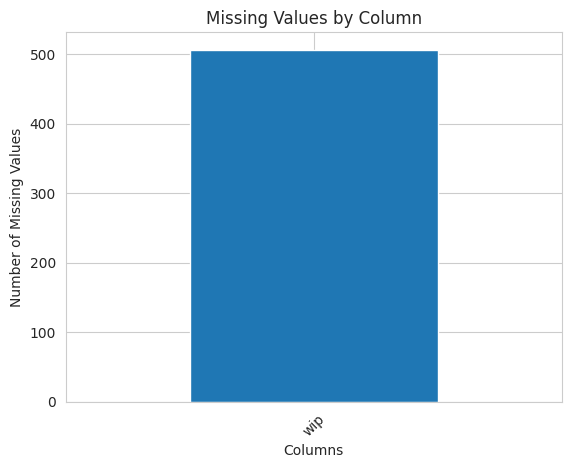

In [ ]:
missing_values = df.isnull().sum()

missing_values[missing_values > 0].plot(kind="bar")
plt.title("Missing Values by Column")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.show()

In [ ]:
df = df.drop(columns=['wip'])

print(df.shape)

(1197, 14)


**Observations**

* After checking the missing values, I found that there are no missing values in the dataset. Therefore, missing value handling is not required, and I skipped that particular preprocessing step.

* I also removed the WIP (Work in Progress) column from the dataset because I decided not to use it for this analysis.


# **3.5 Correlation Analysis**

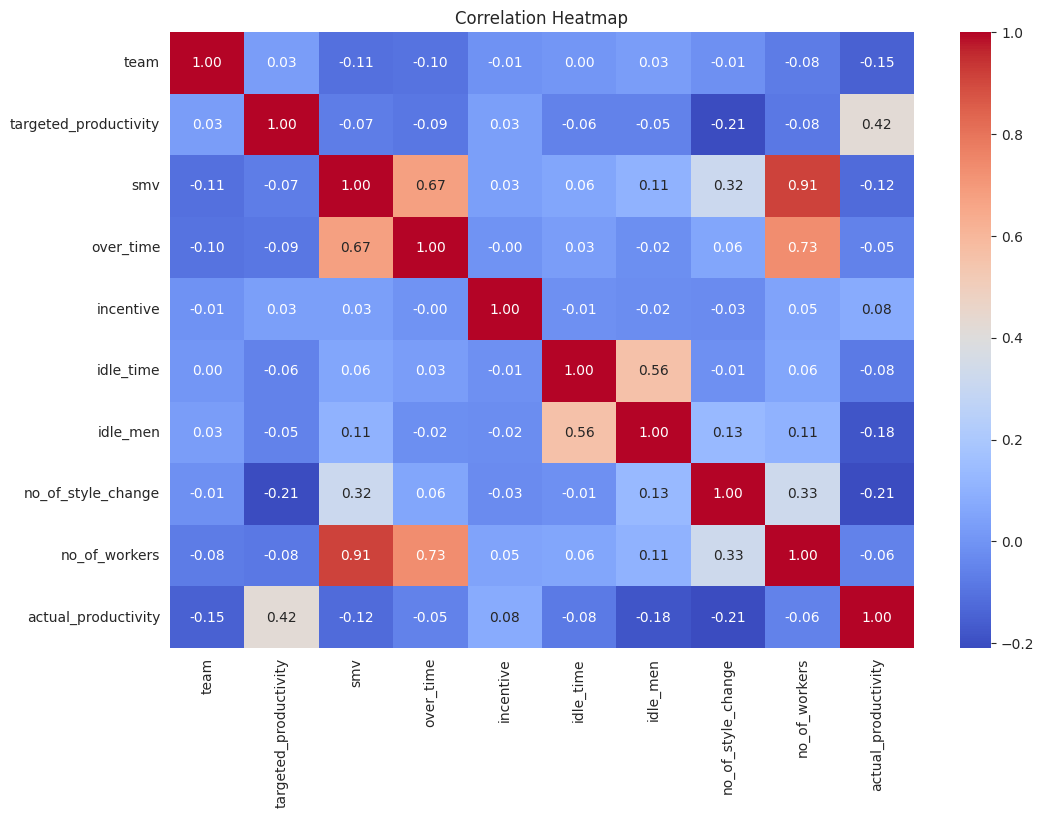


Correlation with Actual Productivity:
actual_productivity      1.000000
targeted_productivity    0.421594
incentive                0.076538
over_time               -0.054206
no_of_workers           -0.057991
idle_time               -0.080851
smv                     -0.122089
team                    -0.148753
idle_men                -0.181734
no_of_style_change      -0.207366
Name: actual_productivity, dtype: float64


In [ ]:
numeric_df = df.select_dtypes(include=np.number)

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

print("\nCorrelation with Actual Productivity:")
print(
    correlation_matrix["actual_productivity"]
    .sort_values(ascending=False)
)

**Observations**

* Correlation analysis helps identify relationships between numerical features.
* Positive correlation indicates that two variables tend to increase together.
* Negative correlation indicates that one variable tends to decrease as the other increases.
* The correlation values help us understand the relationship between features and "actual_productivity".


# **3.6 Visualizations**

# **Visualization 1 — Actual Productivity Distribution**

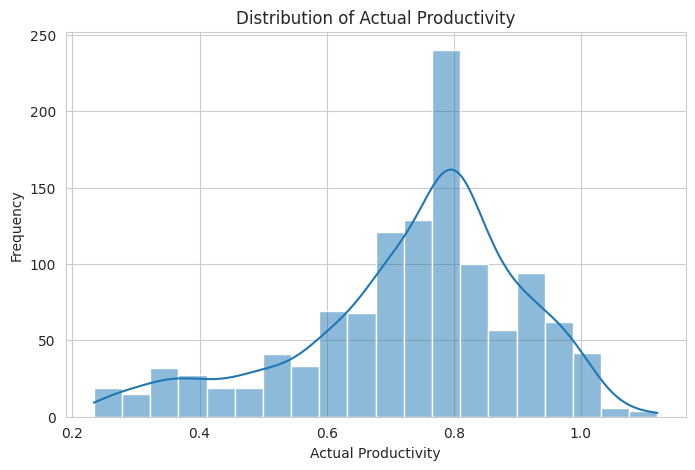

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="actual_productivity",
    bins=20,
    kde=True
)

plt.title("Distribution of Actual Productivity")
plt.xlabel("Actual Productivity")
plt.ylabel("Frequency")
plt.show()

**Observation:**

 This chart shows the distribution of actual productivity values and helps identify the common productivity ranges.

# **Visualization 2 — Targeted vs Actual Productivity**

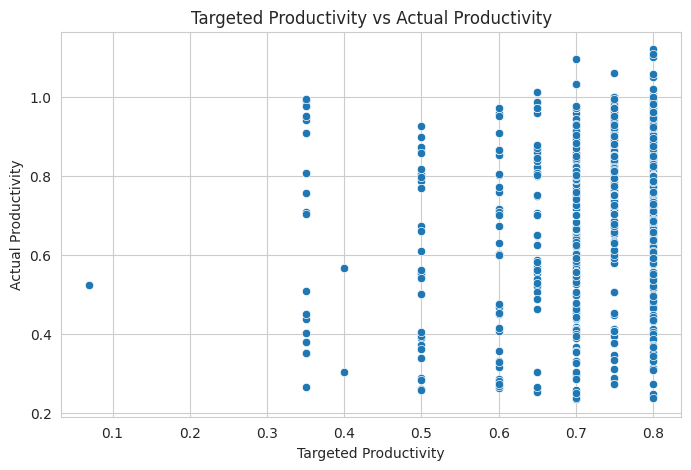

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="targeted_productivity",
    y="actual_productivity"
)

plt.title("Targeted Productivity vs Actual Productivity")
plt.xlabel("Targeted Productivity")
plt.ylabel("Actual Productivity")
plt.show()

**Observation:**

 This chart helps compare targeted productivity with actual productivity and identify whether actual performance follows the production target.


# **Visualization 3 — Productivity by Department**

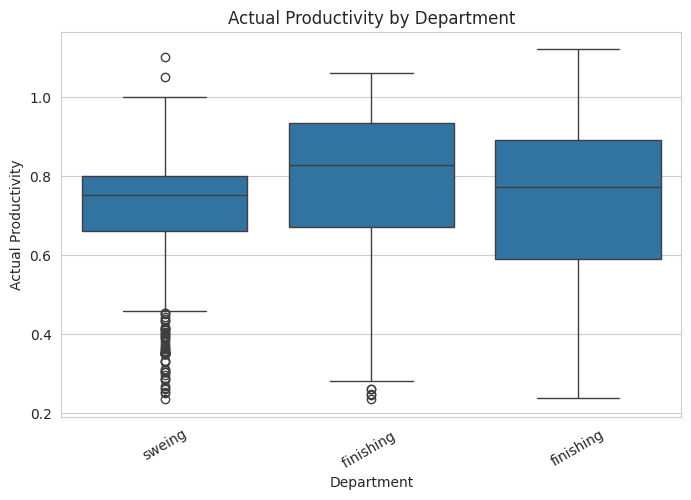

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="department",
    y="actual_productivity"
)

plt.title("Actual Productivity by Department")
plt.xlabel("Department")
plt.ylabel("Actual Productivity")
plt.xticks(rotation=30)
plt.show()

In [ ]:
print(df['department'].unique())
print(df['department'].value_counts())

['sweing' 'finishing ' 'finishing']
department
sweing        691
finishing     257
finishing     249
Name: count, dtype: int64


In [ ]:
df['department'] = df['department'].str.strip()

In [ ]:
print(df['department'].unique())
print(df['department'].value_counts())

['sweing' 'finishing']
department
sweing       691
finishing    506
Name: count, dtype: int64


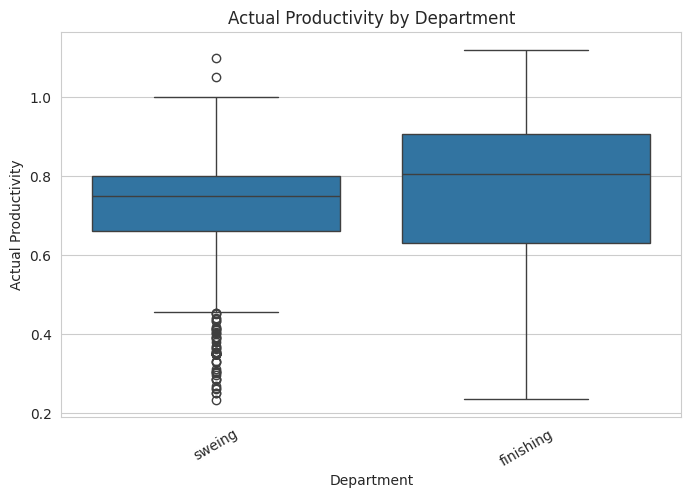

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="department",
    y="actual_productivity"
)

plt.title("Actual Productivity by Department")
plt.xlabel("Department")
plt.ylabel("Actual Productivity")
plt.xticks(rotation=30)
plt.show()

**Observation:**

This visualization compares productivity distributions across departments and helps identify differences in performance.


# **Visualization 4 — Productivity by Day**

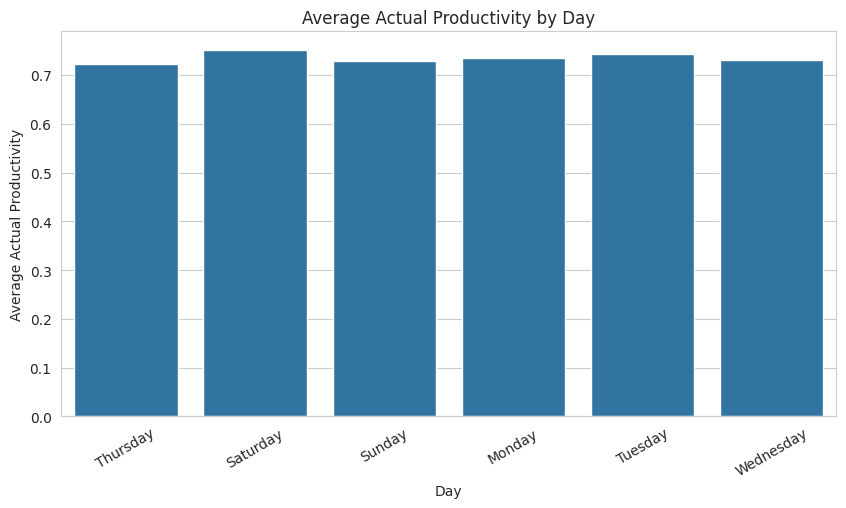

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="day",
    y="actual_productivity",
    errorbar=None
)

plt.title("Average Actual Productivity by Day")
plt.xlabel("Day")
plt.ylabel("Average Actual Productivity")
plt.xticks(rotation=30)
plt.show()

**Observation:**

This chart compares average productivity across different days and helps identify possible day-wise patterns.


# **Visualization 5 — Overtime vs Actual Productivity**

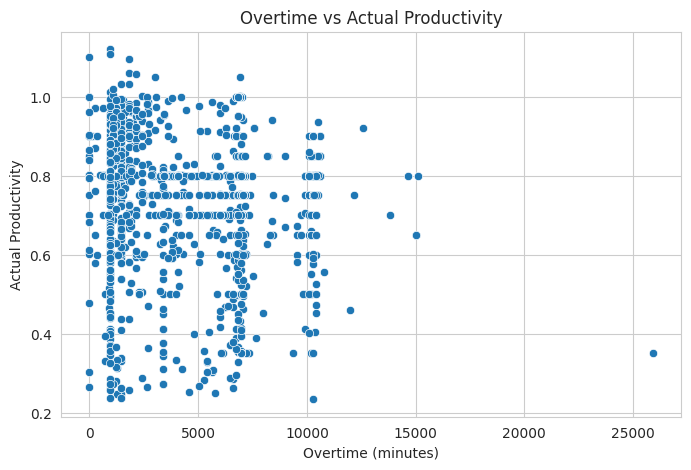

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="over_time",
    y="actual_productivity"
)

plt.title("Overtime vs Actual Productivity")
plt.xlabel("Overtime (minutes)")
plt.ylabel("Actual Productivity")
plt.show()

**Observation:**

This chart helps examine the relationship between overtime and actual productivity. More overtime does not necessarily mean higher productivity.


# **Visualization 6 — Incentive vs Actual Productivity**

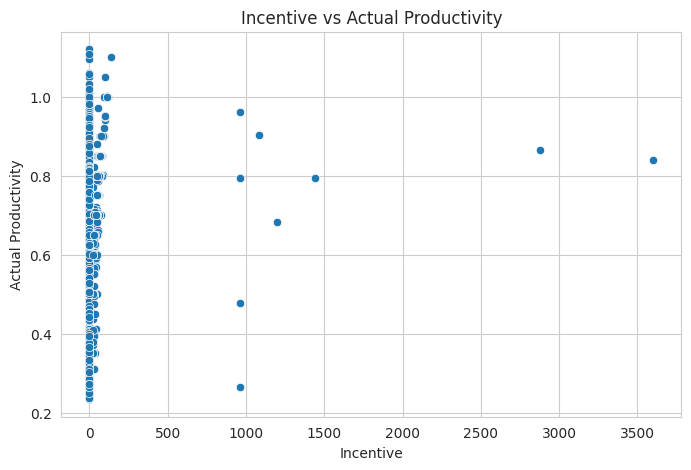

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="incentive",
    y="actual_productivity"
)

plt.title("Incentive vs Actual Productivity")
plt.xlabel("Incentive")
plt.ylabel("Actual Productivity")
plt.show()

**Observation:**

This visualization helps examine whether different incentive amounts are associated with differences in actual productivity.


# **Visualization 7 — Number of Workers vs Actual Productivity**

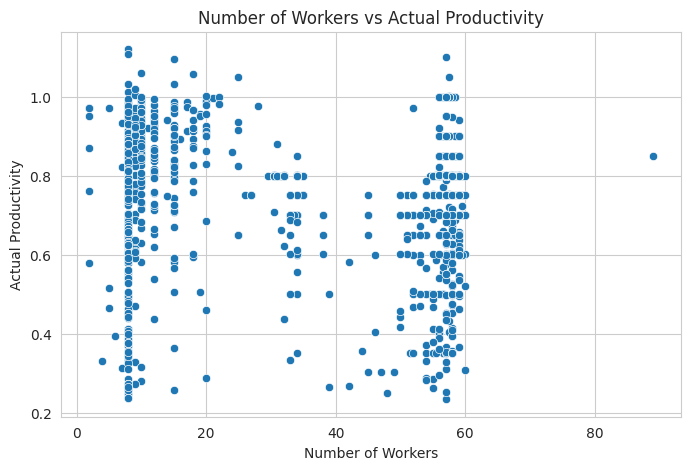

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="no_of_workers",
    y="actual_productivity"
)

plt.title("Number of Workers vs Actual Productivity")
plt.xlabel("Number of Workers")
plt.ylabel("Actual Productivity")
plt.show()

**Observation:**

This chart helps investigate how workforce size is related to actual productivity.


# **Visualization 8 — Productivity by Quarter**

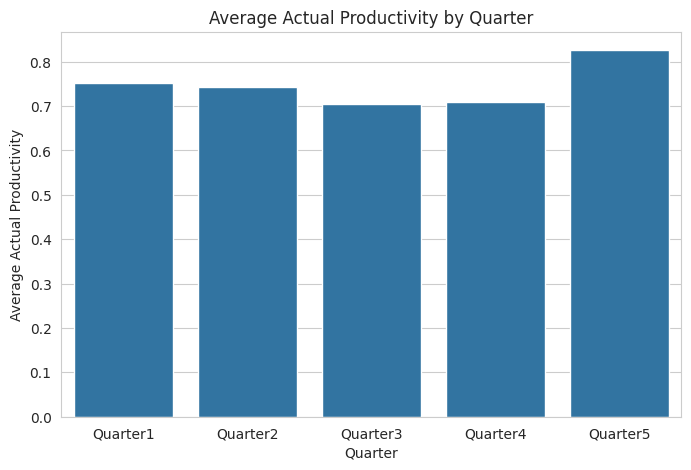

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="quarter",
    y="actual_productivity",
    errorbar=None
)

plt.title("Average Actual Productivity by Quarter")
plt.xlabel("Quarter")
plt.ylabel("Average Actual Productivity")
plt.show()

**Observation:**

This chart compares average productivity across the different quarters of the month.


# **3.7 Key Insights from EDA**

* The dataset contains 1,197 records and 15 columns.
* No missing values were found in the dataset.
* The department column contained inconsistent labels due to extra spaces. These were identified and corrected.
* Correlation analysis helped identify the relationships between numerical features and actual productivity.
* Productivity levels are almost similar across all working days, with slight variations.
* The quarterly analysis shows that Q5 has the highest average productivity, followed by Q1, Q2, Q4, and Q3.
* The box plot identified three potential outliers: one in Sewing and two in Finishing.
* The incentive and overtime visualizations helped explore their relationships with actual productivity.
* Actual productivity is selected as the target variable for the regression models.


# **4. Data Preprocessing**

# **4.1 Missing Value Treatment**

In [ ]:
print(df.isnull().sum())

date                     0
quarter                  0
department               0
day                      0
team                     0
targeted_productivity    0
smv                      0
over_time                0
incentive                0
idle_time                0
idle_men                 0
no_of_style_change       0
no_of_workers            0
actual_productivity      0
dtype: int64


In [ ]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


**Method Used:**

* No imputation method was applied.
* Mean, Median, Mode and SimpleImputer were not required.

**Justification:**

  The dataset was checked for missing values, and no missing values were found in any column. Therefore, no imputation techniques such as Mean, Median, Mode, or SimpleImputer were required. The dataset was retained without missing value treatment.   


# **4.2 Duplicate Handling**

In [ ]:
df.duplicated().sum()

np.int64(0)

**Observation:**

The dataset was checked for duplicate records. No duplicate rows were found (0 duplicates). Therefore, duplicate removal was not required.


# **4.3 Outlier Detection and Treatment**

**Box Plot:**

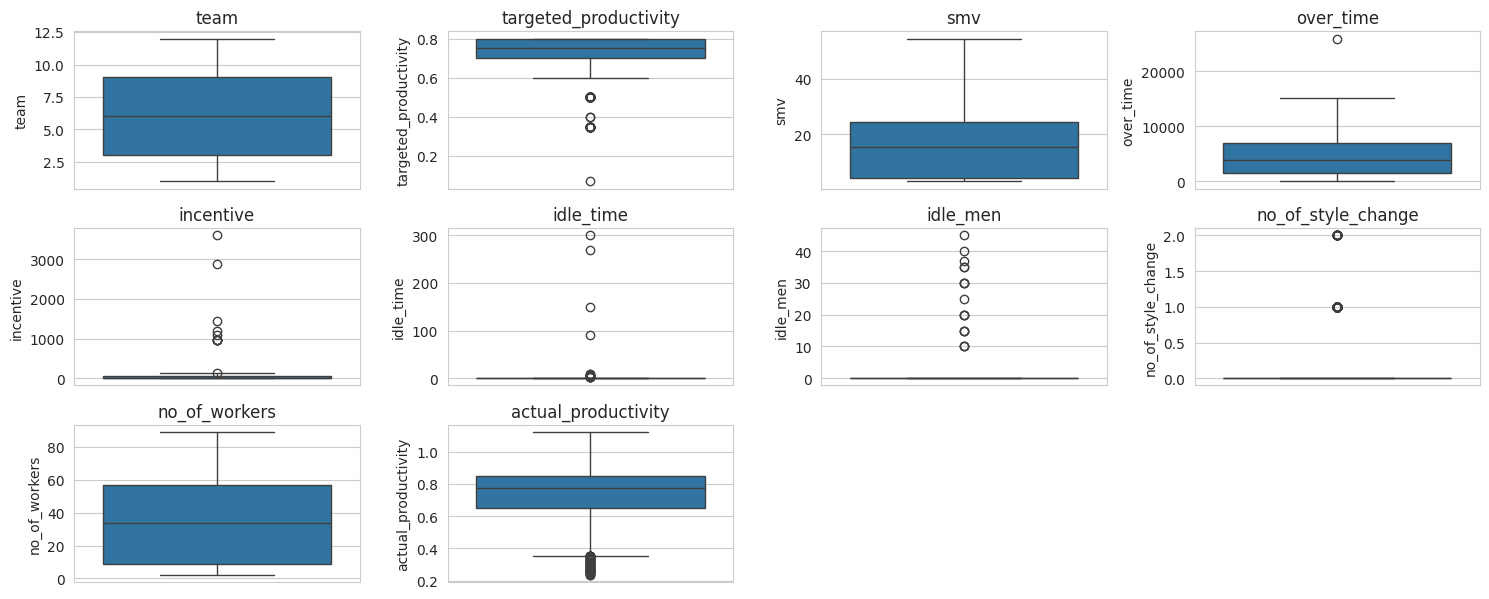

In [ ]:
numeric_columns = df.select_dtypes(include=np.number).columns

plt.figure(figsize=(15, 8))

for i, col in enumerate(numeric_columns, 1):
    plt.subplot(4, 4, i)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

**IQR Method**

In [ ]:
# IQR Outlier Detection Code:

outlier_columns = []

for col in numeric_columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - (1.5 * iqr)
    upper_bound = q3 + (1.5 * iqr)

    outlier_count = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()

    print(col, ":", outlier_count)

    if outlier_count > 0:
        outlier_columns.append(col)

team : 0
targeted_productivity : 79
smv : 0
over_time : 1
incentive : 11
idle_time : 18
idle_men : 18
no_of_style_change : 147
no_of_workers : 0
actual_productivity : 54


**Observation:**

* Outliers were identified using Boxplots and the IQR method. Several numerical columns were found to contain potential outliers.

* However, no outlier treatment was performed at this stage. Outlier capping will be carried out after the Train-Test Split during the model preprocessing stage to avoid data leakage.

* The IQR bounds will be calculated using the training data and applied to the testing data using the same bounds.


# **4.4 Skewness Treatment**

**Before Transformation**

In [ ]:
# skewness check

numeric_columns = df.select_dtypes(include=np.number).columns

skewness_before = df[numeric_columns].skew()

print(skewness_before)

team                      0.009848
targeted_productivity    -2.144150
smv                       0.405937
over_time                 0.673287
incentive                15.790746
idle_time                20.545425
idle_men                  9.855079
no_of_style_change        2.942506
no_of_workers            -0.111740
actual_productivity      -0.807492
dtype: float64


**Distribution Before Transformation**

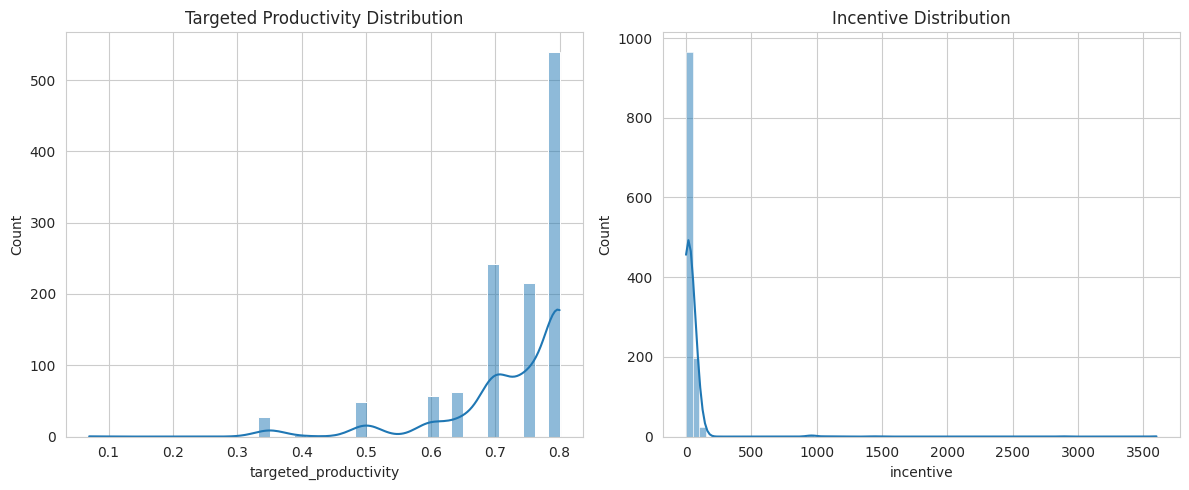

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df['targeted_productivity'], kde=True)
plt.title('Targeted Productivity Distribution')

plt.subplot(1, 2, 2)
sns.histplot(df['incentive'], kde=True)
plt.title('Incentive Distribution')

plt.tight_layout()
plt.show()

**Observation:**

* Skewness analysis was performed using the skewness values and histogram plots. The analysis showed that the "targeted_productivity" column was negatively skewed, while the "incentive" column showed moderate positive skewness. Most of the other numerical features were approximately symmetric.

* No transformation was performed at this stage. The **"Square Root Transformation" for the "incentive"** column will be considered after the Train-Test Split during model preprocessing. This approach helps prevent data leakage. The target variable, "actual_productivity", was retained without transformation.


# **4.5 Encoding**

Categorical features such as `department`, `day`, and `quarter` were identified in the dataset.

**Label Encoding:**

Label Encoding was not selected because assigning numerical values to nominal categories may introduce an artificial ordinal relationship between them. For example, one department may receive a value of 0 and another department may receive a value of 1, even though no numerical order exists between them.

**One Hot Encoding:**

One Hot Encoding was selected as the appropriate method for nominal categorical features. It converts each category into separate binary columns (0 and 1) without introducing an artificial numerical order.

**Implementation:**

One Hot Encoding was not performed at this stage. It will be implemented after the Train-Test Split using `ColumnTransformer` and `make_pipeline()`. The encoder will be fitted only on the training data and then applied to the testing data to prevent data leakage.


# **4.6 Feature Scaling**

* Feature Scaling methods such as Standardization (StandardScaler) and Normalization (MinMaxScaler) were studied.

* However, separate Feature Scaling was not performed at this stage because the scaling process will be incorporated into the Machine Learning workflow using the `make_pipeline()` method during model building.

* The appropriate scaling technique will be selected based on the requirements of the machine learning algorithm. This approach helps maintain a consistent preprocessing workflow and prevents data leakage.


# **4.7 Train-Test Split**

In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['actual_productivity', 'date'])

y = df['actual_productivity']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (957, 12)
X_test: (240, 12)
y_train: (957,)
y_test: (240,)


In [ ]:
# import libraries

import pandas as pd
import numpy as np

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LinearRegression

In [ ]:
# Identify Numerical and Categorical Columns

categorical_columns = ['department', 'day', 'quarter', 'team']

numeric_columns = X_train.select_dtypes(include='number').columns.tolist()

numeric_columns.remove('incentive')   # here incentive-i square root transformation seiya vendum. so remove.

numeric_columns.remove('team')    # same above reason

In [ ]:
# Create Custom Outlier Capping Transformer

class OutlierCapping(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        q1 = X.quantile(0.25)
        q3 = X.quantile(0.75)
        iqr = q3 - q1

        self.lower_bounds = q1 - 1.5 * iqr
        self.upper_bounds = q3 + 1.5 * iqr

        return self

    def transform(self, X):
        X = X.copy()
        return X.clip(self.lower_bounds, self.upper_bounds, axis=1)

In [ ]:
# Create Numerical Pipeline

numeric_pipeline = make_pipeline(
    OutlierCapping(),
    StandardScaler()
)

In [ ]:
# Create Incentive Pipeline

print(X_train['incentive'].min())     # here check without negative values(because square root only posive values)

0


In [ ]:
incentive_pipeline = make_pipeline(
    OutlierCapping(),
    FunctionTransformer(np.sqrt),
    StandardScaler()
)

In [ ]:
# Create Categorical Pipeline

categorical_pipeline = make_pipeline(
    OneHotEncoder(handle_unknown='ignore')
)

In [ ]:
# Combine Using ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_pipeline, numeric_columns),
        ('inc', incentive_pipeline, ['incentive']),
        ('cat', categorical_pipeline, categorical_columns)
    ]
)

# **5. Feature Engineering & Feature Selection**

# **5.1 Feature Engineering**

* The existing features were examined to identify opportunities for creating new features.

* The dataset already contains relevant information such as overtime, number of workers, incentives, and standard minute value.

* No additional features were created at this stage because the existing features were considered sufficient for the initial model development.


# **5.2 Correlation-Based Feature Selection**

In [ ]:
# Correlation Analysis

correlation_data = X_train.select_dtypes(include='number').copy()

correlation_data['actual_productivity'] = y_train

correlation_matrix = correlation_data.corr()

print(correlation_matrix['actual_productivity'].sort_values(ascending=False))

actual_productivity      1.000000
targeted_productivity    0.431037
incentive                0.066243
over_time               -0.051634
no_of_workers           -0.057404
idle_time               -0.086370
smv                     -0.117555
team                    -0.170332
idle_men                -0.202731
no_of_style_change      -0.212743
Name: actual_productivity, dtype: float64


**Correlation Heatmap:**

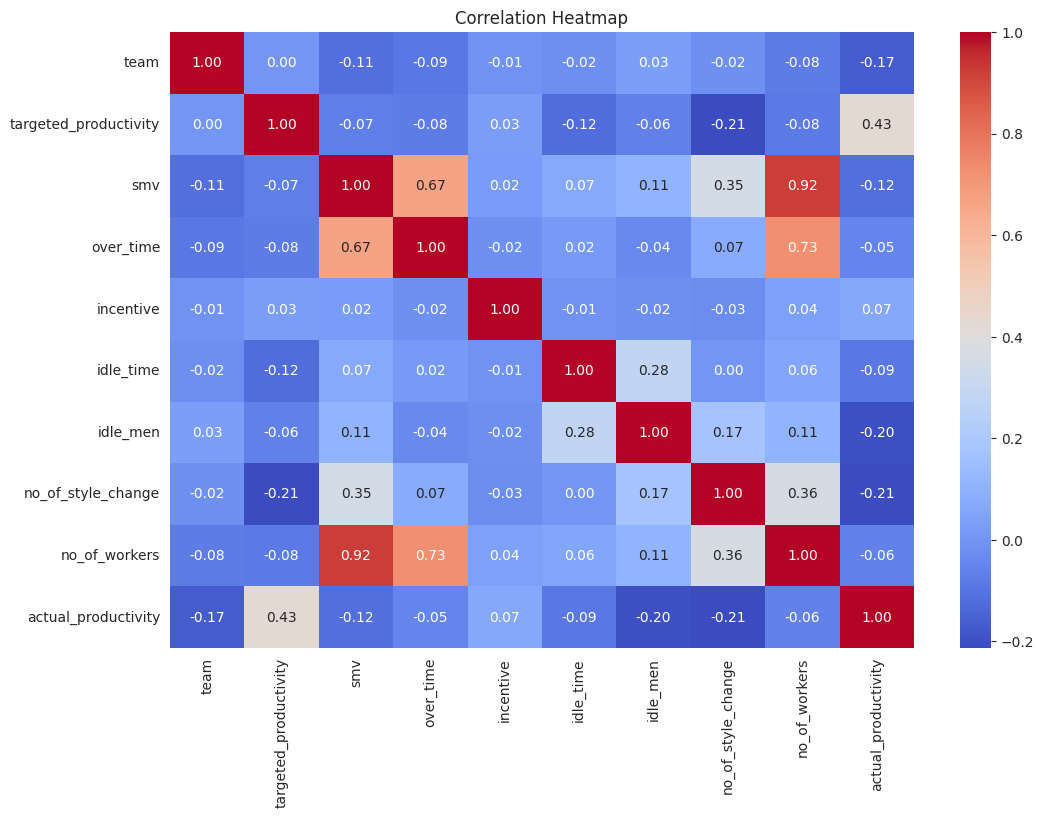

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

**Observation:**

The number of workers has a strong positive correlation (0.94) with the Sewing department and a strong negative correlation (-0.94) with the Finishing department. This indicates that workforce distribution differs between the two departments.


# **5.3 SelectKBest**

SelectKBest is used to identify the most important features for predicting actual productivity. It selects features based on their statistical relationship with the target variable. The feature selection process will be **performed after encoding**, using the training data to avoid data leakage.

# **5.4 Final Feature Set**

The final feature set will be selected based on correlation analysis and **SelectKBest results**. These selected features will be used for model building to predict actual productivity.


# **6. Model Building**

In [ ]:
# checking now dataset

print("X columns:", X.columns.tolist())

print("X_train columns:", X_train.columns.tolist())

print("Department exists:", 'department' in X_train.columns)

X columns: ['quarter', 'department', 'day', 'team', 'targeted_productivity', 'smv', 'over_time', 'incentive', 'idle_time', 'idle_men', 'no_of_style_change', 'no_of_workers']
X_train columns: ['quarter', 'department', 'day', 'team', 'targeted_productivity', 'smv', 'over_time', 'incentive', 'idle_time', 'idle_men', 'no_of_style_change', 'no_of_workers']
Department exists: True


In [ ]:
# load old dataset

df = pd.read_csv('https://raw.githubusercontent.com/sathyabamasrsep13/Garment-Employee-Productivity-Analysis/refs/heads/main/garments_worker_productivity.csv')

In [ ]:
# drop columns

df = df.drop(columns=['wip'])

df['department'] = df['department'].str.strip()

In [ ]:
print(df.columns.tolist())

['date', 'quarter', 'department', 'day', 'team', 'targeted_productivity', 'smv', 'over_time', 'incentive', 'idle_time', 'idle_men', 'no_of_style_change', 'no_of_workers', 'actual_productivity']


In [ ]:
# Train-test split

X = df.drop(columns=['actual_productivity', 'date'])

y = df['actual_productivity']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
print(X_train.columns.tolist())

['quarter', 'department', 'day', 'team', 'targeted_productivity', 'smv', 'over_time', 'incentive', 'idle_time', 'idle_men', 'no_of_style_change', 'no_of_workers']


In [ ]:
# Numerical & Categorical Columns

categorical_columns = ['department', 'day', 'quarter', 'team']

numeric_columns = X_train.select_dtypes(include='number').columns.tolist()

numeric_columns.remove('incentive')
numeric_columns.remove('team')

In [ ]:
# make new preprocessor

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_pipeline, numeric_columns),
        ('inc', incentive_pipeline, ['incentive']),
        ('cat', categorical_pipeline, categorical_columns)
    ]
)

In [ ]:
# Model Pipeline

model = make_pipeline(
    preprocessor,
    LinearRegression()
)

In [ ]:
# Model Training

model.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('outliercapping',
                                                                   OutlierCapping()),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['targeted_productivity',
                                                   'smv', 'over_time',
                                                   'idle_time', 'idle_men',
                                                   'no_of_style_change',
                                                   'no_of_workers']),
                                                 ('inc',
                                                  Pipeline(steps=[('outliercapping',
                                                                   OutlierCapping()),
                                                                  ('functiontransformer',
                                                                   FunctionTransformer(func=<ufunc 'sqrt'>)),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['incentive']),
                                                 ('cat',
                                                  Pipeline(steps=[('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['department', 'day',
                                                   'quarter', 'team'])])),
                ('linearregression', LinearRegression())])

In [ ]:
# Prediction

y_pred = model.predict(X_test)

In [ ]:
# Actual vs Predicted Comparison

comparison = pd.DataFrame({
    'Actual Productivity': y_test.values,
    'Predicted Productivity': y_pred
})

print(comparison.head(10))

   Actual Productivity  Predicted Productivity
0             0.268214                0.501093
1             0.800359                0.761442
2             0.681061                0.786011
3             0.325000                0.720055
4             0.667604                0.765734
5             0.800980                0.677777
6             0.768847                0.589949
7             0.768847                0.627761
8             0.650417                0.614878
9             0.750396                0.731566


# **6.1 Model Evaluation**

In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

In [ ]:
r2 = r2_score(y_test, y_pred)

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

print("R2 Score:", r2)
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)

R2 Score: 0.3093102616077743
MAE: 0.09887919428703379
MSE: 0.018339516156867693
RMSE: 0.13542346974165037


**Observation:**

* The Linear Regression model achieved an R² score of 0.3093, indicating that it explains approximately 30.93% of the variation in actual productivity.

* The MAE is 0.0989 and the RMSE is 0.1354. The model shows limited predictive performance, so further model improvement is required.


# **6.2 Decision Tree Regressor**

In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

In [ ]:
decision_tree_model = make_pipeline(
    preprocessor,
    DecisionTreeRegressor(random_state=42)
)

In [ ]:
decision_tree_model.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('outliercapping',
                                                                   OutlierCapping()),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['targeted_productivity',
                                                   'smv', 'over_time',
                                                   'idle_time', 'idle_men',
                                                   'no_of_style_change',
                                                   'no_of_workers']),
                                                 ('inc',
                                                  Pipeline(steps=[('outliercapping',
                                                                   OutlierCapping()),
                                                                  ('functiontransformer',
                                                                   FunctionTransformer(func=<ufunc 'sqrt'>)),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['incentive']),
                                                 ('cat',
                                                  Pipeline(steps=[('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['department', 'day',
                                                   'quarter', 'team'])])),
                ('decisiontreeregressor',
                 DecisionTreeRegressor(random_state=42))])

In [ ]:
y_pred_dt = decision_tree_model.predict(X_test)

In [ ]:
r2_dt = r2_score(y_test, y_pred_dt)
mae_dt = mean_absolute_error(y_test, y_pred_dt)
mse_dt = mean_squared_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mse_dt)

print("Decision Tree R2 Score:", r2_dt)
print("Decision Tree MAE:", mae_dt)
print("Decision Tree MSE:", mse_dt)
print("Decision Tree RMSE:", rmse_dt)

Decision Tree R2 Score: 0.3488490775968448
Decision Tree MAE: 0.07736622806666667
Decision Tree MSE: 0.017289663068934313
Decision Tree RMSE: 0.13149016339230213


**Observation:**

* The Decision Tree Regressor performed better than Linear Regression.

* It achieved a higher R² score of 0.3488 and lower error values.

* Therefore, Decision Tree performed better among these two models.
* However, further improvement is required to achieve better prediction accuracy.


# **6.3 Random Forest Regressor**

In [ ]:
from sklearn.ensemble import RandomForestRegressor

In [ ]:
random_forest_model = make_pipeline(
    preprocessor,
    RandomForestRegressor(random_state=42)
)

In [ ]:
random_forest_model.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('outliercapping',
                                                                   OutlierCapping()),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['targeted_productivity',
                                                   'smv', 'over_time',
                                                   'idle_time', 'idle_men',
                                                   'no_of_style_change',
                                                   'no_of_workers']),
                                                 ('inc',
                                                  Pipeline(steps=[('outliercapping',
                                                                   OutlierCapping()),
                                                                  ('functiontransformer',
                                                                   FunctionTransformer(func=<ufunc 'sqrt'>)),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['incentive']),
                                                 ('cat',
                                                  Pipeline(steps=[('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['department', 'day',
                                                   'quarter', 'team'])])),
                ('randomforestregressor',
                 RandomForestRegressor(random_state=42))])

In [ ]:
y_pred_rf = random_forest_model.predict(X_test)

In [ ]:
r2_rf = r2_score(y_test, y_pred_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)

print("Random Forest R2 Score:", r2_rf)
print("Random Forest MAE:", mae_rf)
print("Random Forest MSE:", mse_rf)
print("Random Forest RMSE:", rmse_rf)

Random Forest R2 Score: 0.5211275378810489
Random Forest MAE: 0.07115629222974998
Random Forest MSE: 0.01271524501949712
Random Forest RMSE: 0.11276189524612079


**Observation:**

* Three regression models were evaluated: Linear Regression, Decision Tree Regressor, and Random Forest Regressor.

* Among these models, Random Forest achieved the highest R² score of 0.5211 and the lowest error values (MAE: 0.0712, MSE: 0.0127, RMSE: 0.1128).

* Therefore, Random Forest performed better than the other two models in predicting actual productivity.


# **6.4 Hyperparameter Tuning – GridSearchCV**

In [ ]:
from sklearn.model_selection import GridSearchCV

In [ ]:
param_grid = {
    'randomforestregressor__n_estimators': [100, 200],
    'randomforestregressor__max_depth': [None, 10, 20],
    'randomforestregressor__min_samples_split': [2, 5],
    'randomforestregressor__min_samples_leaf': [1, 2]
}

In [ ]:
# Create GridSearchCV

grid_search = GridSearchCV(
    estimator=random_forest_model,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

In [ ]:
# Fit the Model

grid_search.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('columntransformer',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('outliercapping',
                                                                                          OutlierCapping()),
                                                                                         ('standardscaler',
                                                                                          StandardScaler())]),
                                                                         ['targeted_productivity',
                                                                          'smv',
                                                                          'over_time',
                                                                          'idle_time',
                                                                          'idle_men',
                                                                          'no_of_style_change',
                                                                          'no_of_workers']),
                                                                        ('inc',
                                                                         Pipeline(steps=[('outliercapping',
                                                                                          OutlierCap...
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         ['department',
                                                                          'day',
                                                                          'quarter',
                                                                          'team'])])),
                                       ('randomforestregressor',
                                        RandomForestRegressor(random_state=42))]),
             n_jobs=-1,
             param_grid={'randomforestregressor__max_depth': [None, 10, 20],
                         'randomforestregressor__min_samples_leaf': [1, 2],
                         'randomforestregressor__min_samples_split': [2, 5],
                         'randomforestregressor__n_estimators': [100, 200]},
             scoring='r2')

In [ ]:
# Find the Best Parameters

print("Best Parameters:", grid_search.best_params_)

print("Best Cross Validation R2 Score:", grid_search.best_score_)

Best Parameters: {'randomforestregressor__max_depth': None, 'randomforestregressor__min_samples_leaf': 2, 'randomforestregressor__min_samples_split': 5, 'randomforestregressor__n_estimators': 200}
Best Cross Validation R2 Score: 0.4657209101612915


**Observation:**

* GridSearchCV with 5-fold cross-validation was used to identify the best hyperparameters for the Random Forest Regressor.

* The best parameters were 200 estimators, no maximum depth limit, a minimum of 5 samples for splitting, and a minimum of 2 samples per leaf.
* The best cross-validation R² score was 0.4657.


# **6.5 Tuned Model Evaluation**

In [ ]:
best_model = grid_search.best_estimator_

y_pred_tuned = best_model.predict(X_test)

r2_tuned = r2_score(y_test, y_pred_tuned)
mae_tuned = mean_absolute_error(y_test, y_pred_tuned)
mse_tuned = mean_squared_error(y_test, y_pred_tuned)
rmse_tuned = np.sqrt(mse_tuned)

print("Tuned Random Forest R2 Score:", r2_tuned)
print("Tuned Random Forest MAE:", mae_tuned)
print("Tuned Random Forest MSE:", mse_tuned)
print("Tuned Random Forest RMSE:", rmse_tuned)

Tuned Random Forest R2 Score: 0.5248930443757992
Tuned Random Forest MAE: 0.07120304604659908
Tuned Random Forest MSE: 0.012615261534350787
Tuned Random Forest RMSE: 0.11231768130775664


**Observation:**

* After hyperparameter tuning using GridSearchCV, the Random Forest model achieved a slightly improved R² score of 0.5249 compared to 0.5211 before tuning.

* The MSE and RMSE values also decreased slightly, while the MAE increased marginally.

* Overall, the tuned Random Forest model showed a small improvement in predictive performance.


# **6.6 Actual vs Predicted Visualization**

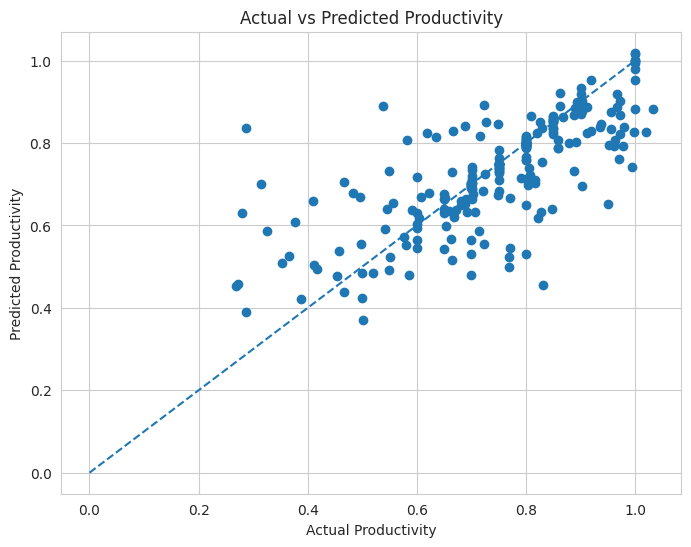

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_tuned)

plt.xlabel('Actual Productivity')
plt.ylabel('Predicted Productivity')
plt.title('Actual vs Predicted Productivity')

plt.plot([0, 1], [0, 1], linestyle='--')

plt.show()

**Observation:**

* The Actual vs Predicted Productivity scatter plot shows a positive linear pattern.

* Some data points are close to the diagonal reference line, indicating better predictions, while others are far from the line, indicating prediction errors.

* Overall, the model shows a moderate prediction performance.


# **6.7 Gradient Boosting Regressor**

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

In [ ]:
gb_model = make_pipeline(
    preprocessor,
    GradientBoostingRegressor(random_state=42)
)

In [ ]:
gb_model.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('outliercapping',
                                                                   OutlierCapping()),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['targeted_productivity',
                                                   'smv', 'over_time',
                                                   'idle_time', 'idle_men',
                                                   'no_of_style_change',
                                                   'no_of_workers']),
                                                 ('inc',
                                                  Pipeline(steps=[('outliercapping',
                                                                   OutlierCapping()),
                                                                  ('functiontransformer',
                                                                   FunctionTransformer(func=<ufunc 'sqrt'>)),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['incentive']),
                                                 ('cat',
                                                  Pipeline(steps=[('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['department', 'day',
                                                   'quarter', 'team'])])),
                ('gradientboostingregressor',
                 GradientBoostingRegressor(random_state=42))])

In [ ]:
y_pred_gb = gb_model.predict(X_test)

In [ ]:
r2_gb = r2_score(y_test, y_pred_gb)
mae_gb = mean_absolute_error(y_test, y_pred_gb)
mse_gb = mean_squared_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mse_gb)

print("Gradient Boosting R2 Score:", r2_gb)
print("Gradient Boosting MAE:", mae_gb)
print("Gradient Boosting MSE:", mse_gb)
print("Gradient Boosting RMSE:", rmse_gb)

Gradient Boosting R2 Score: 0.44464777623399454
Gradient Boosting MAE: 0.08182206504751646
Gradient Boosting MSE: 0.014745971330364998
Gradient Boosting RMSE: 0.12143299111182676


**Observation:**

* The Gradient Boosting Regressor was implemented to predict actual garment employee productivity.
* It uses multiple decision trees sequentially, where each new tree attempts to reduce the errors made by the previous trees.
* Its performance was evaluated using R² Score, MAE, MSE, and RMSE.
* The results were compared with other regression models to identify the best-performing model.


# **Final Model: Tuned Random Forest Regressor**

**Observation:**

* Based on the evaluation results, the Tuned Random Forest Regressor was selected as the final model.

* It achieved the highest R² score of 0.5249 among the evaluated models. It also produced the lowest MSE and RMSE values.

* Therefore, it was selected as the best-performing model for predicting garment employee productivity.


# **7. Conclusion**

* This project focused on analyzing and predicting garment employee productivity using Machine Learning techniques.

* The dataset was explored through Exploratory Data Analysis (EDA) to understand productivity patterns and relationships between different features. Data preprocessing techniques such as handling inconsistent values, encoding categorical variables, outlier treatment, and feature scaling were applied.

* Three regression models were developed: Linear Regression, Decision Tree Regressor, and Random Forest Regressor. Their performances were evaluated using R² Score, MAE, MSE, and RMSE.

* Among these models, the Tuned Random Forest Regressor achieved the best performance with an R² score of 0.5249.

* This project demonstrates how Machine Learning can help analyze employee productivity and support better production planning and workforce management in the garment industry.


# **"Thank you"**